# Part1: Hyperparameter Tuning for SVMs and Random Forests on Wine Quality Dataset


## CONTEXT
This project is part of data analysis and machine learning applied to wine classification. The main objective is to develop and evaluate models capable of predicting the type of wine (cultivar) from its chemical characteristics. The dataset used, "wine", is a classic scikit-learn dataset, containing information about different wines and their chemical properties. The analysis aims to explore the performance of two classification algorithms, SVM and Random Forest, with an emphasis on the importance of data preprocessing and hyperparameter optimization to obtain accurate and reliable results.

## VARIABLES DESCRIPTION

The "wine" dataset contains chemical analysis data of wines grown in the same region in Italy but derived from three different cultivars. The dataset includes the following features:

**Features:**

1.  **alcohol:** Alcohol content of the wine (% vol).
2.  **malic_acid:** Malic acid content of the wine (g/L).
3.  **ash:** Ash content of the wine (g/L).
4.  **alcalinity_of_ash:** Alcalinity of ash in the wine (g/L).
5.  **magnesium:** Magnesium content of the wine (mg/L).
6.  **total_phenols:** Total phenols content of the wine (mg/L).
7.  **flavanoids:** Flavanoids content of the wine (mg/L).
8.  **nonflavanoid_phenols:** Nonflavanoid phenols content of the wine (mg/L).
9.  **proanthocyanins:** Proanthocyanins content of the wine (mg/L).
10. **color_intensity:** Color intensity of the wine.
11. **hue:** Hue of the wine.
12. **od280/od315_of_diluted_wines:** OD280/OD315 ratio of diluted wines.
13. **proline:** Proline content of the wine (mg/L).

**Target Variable:**

* **target:** The type of wine (cultivar), represented by the integers 0, 1, and 2.

**Importance of Variables:**

These variables are crucial for characterizing the chemical and organoleptic properties of wines. They can be used to:

* Classify wines based on their cultivar.
* Predict wine quality.
* Understand the factors that influence wine quality.

## Data loading and exploration

In [1]:
#Upload libraries
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.datasets import load_wine
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler

In [2]:
# Load dataset
wine = load_wine()
X, y = wine.data, wine.target

In [3]:
# Convert to DataFrame for easy analysis
df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y

In [4]:
# Explanatory Data Analysis(EDA)
print(df.head())
print(df.info())
print(df.describe())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

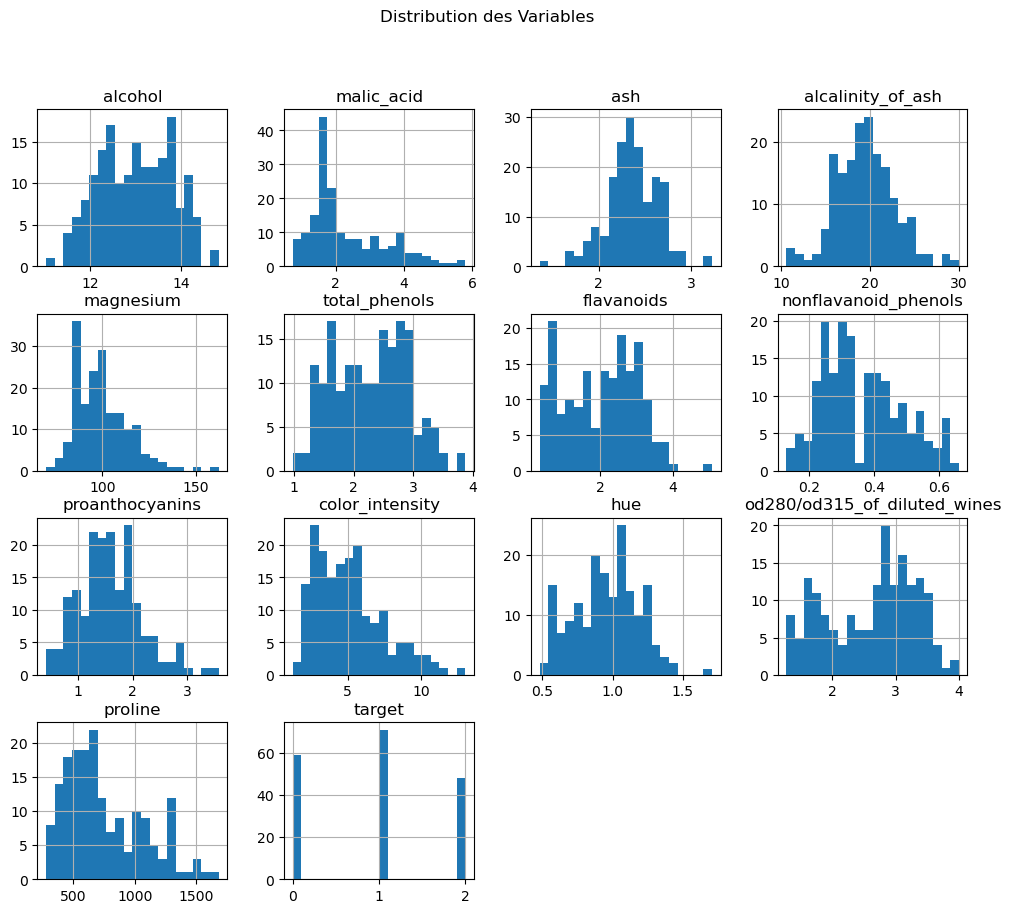

In [5]:
# Distribution des variables
df.hist(figsize=(12, 10), bins=20)
plt.suptitle('Distribution des Variables')
plt.show()

#### Approximately normal distributions are observed for some variables such as "total_phenols" and "od280/od315_of_diluted_wines", while others, such as "malic_acid" and "color_intensity", show marked asymmetry and the presence of outliers. The variable "target" illustrates the distribution of the three wine classes, highlighting a slight imbalance

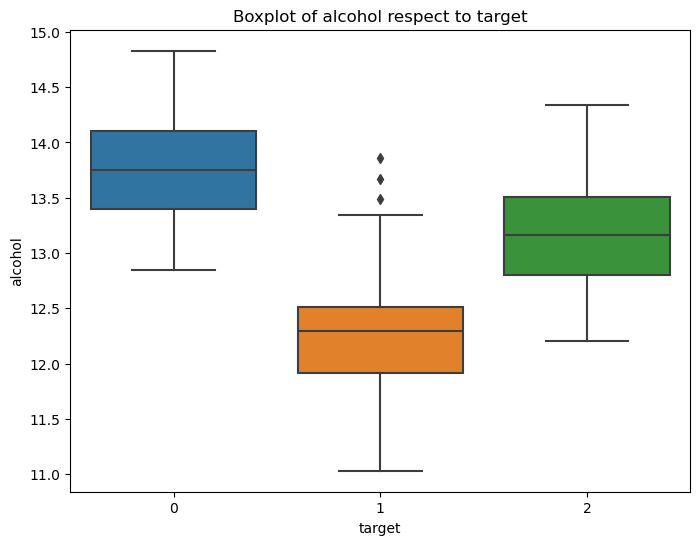

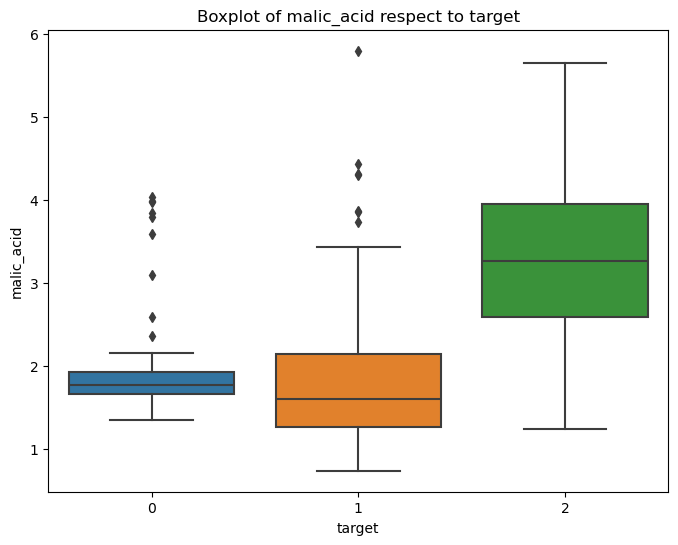

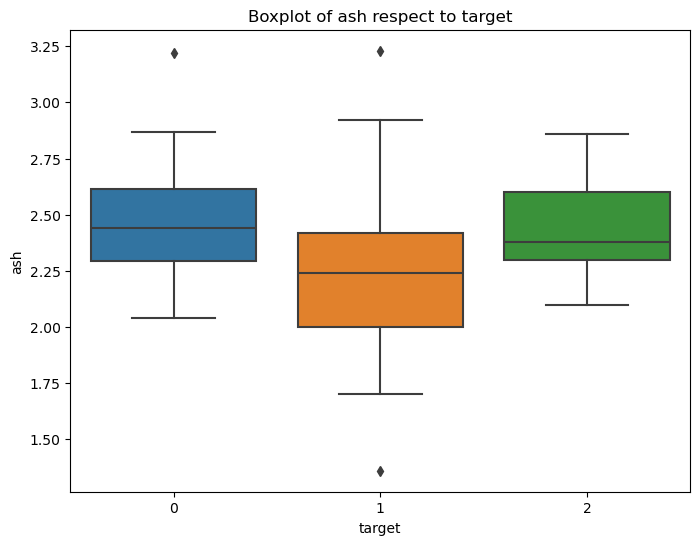

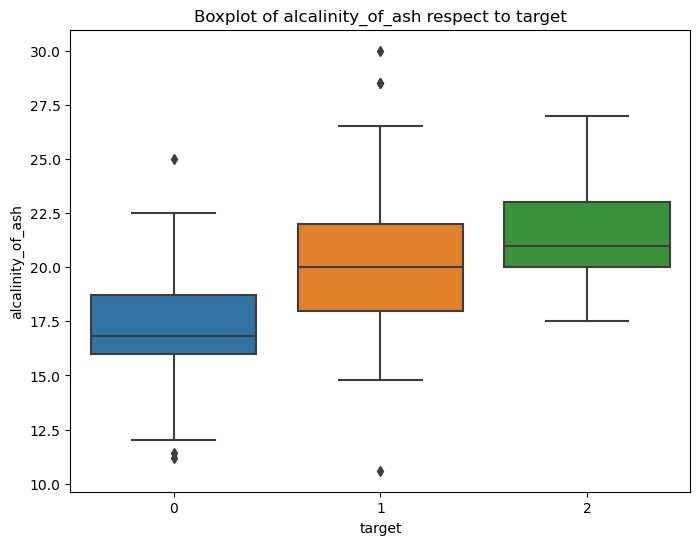

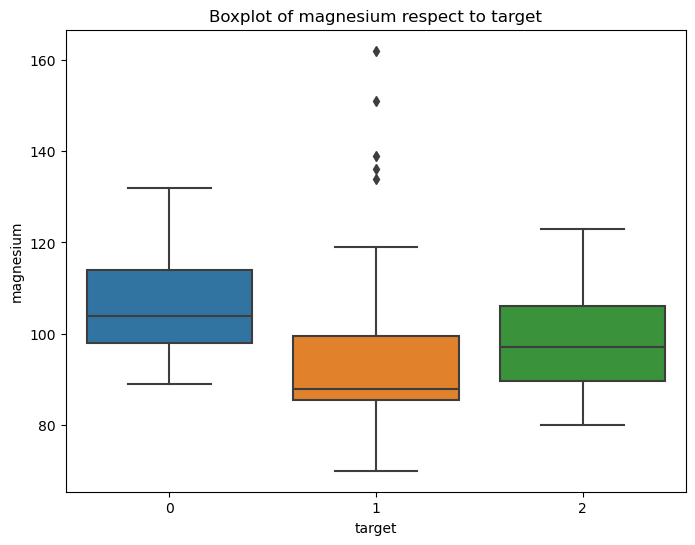

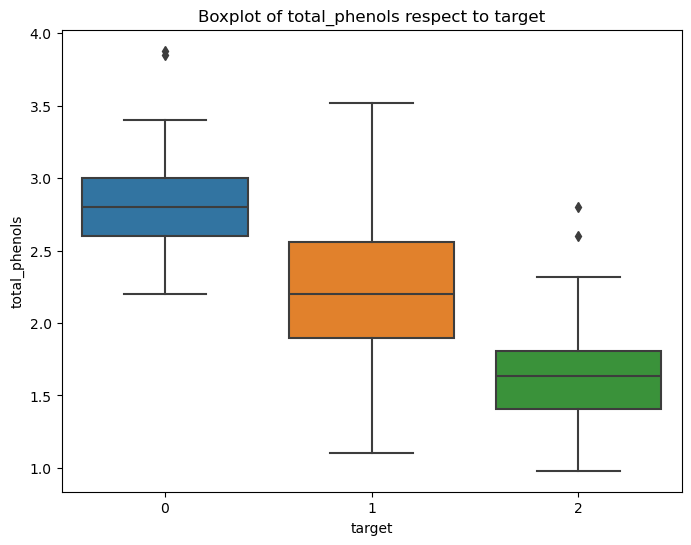

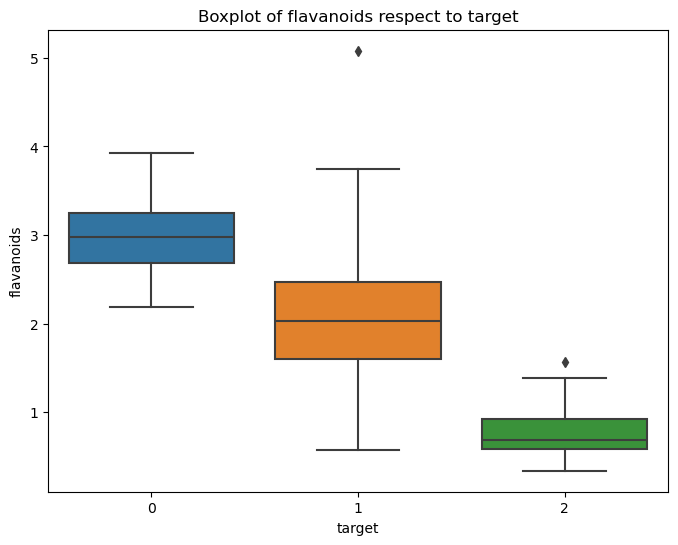

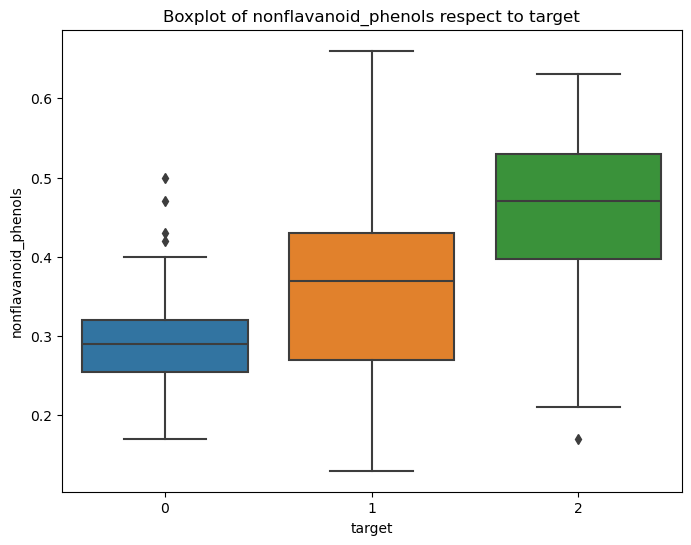

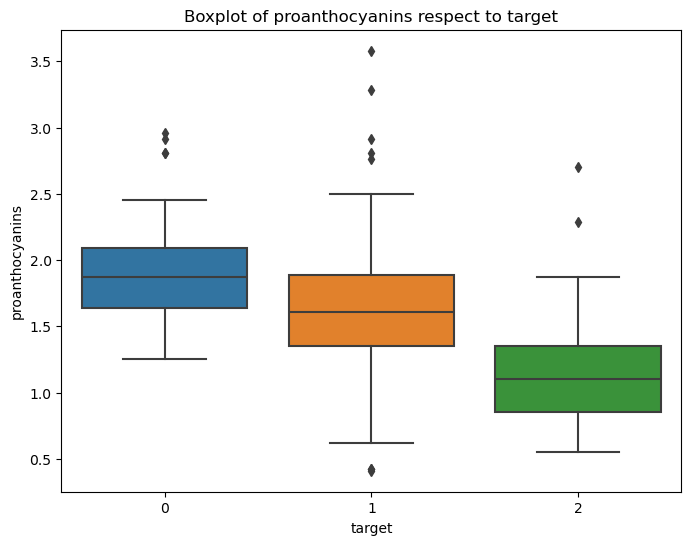

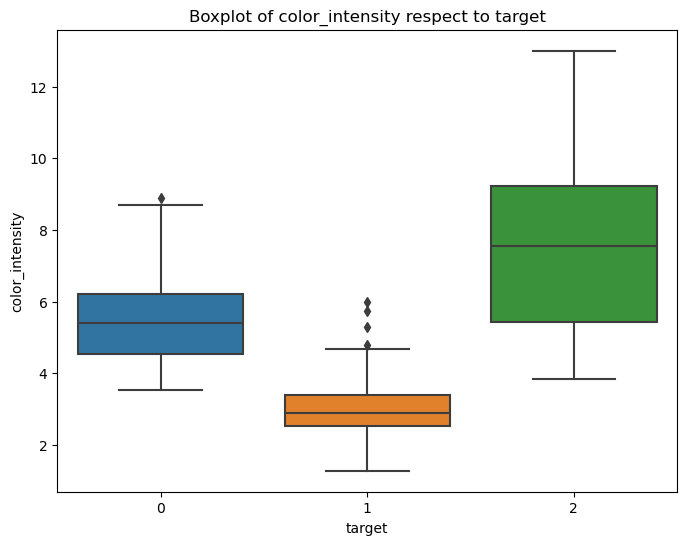

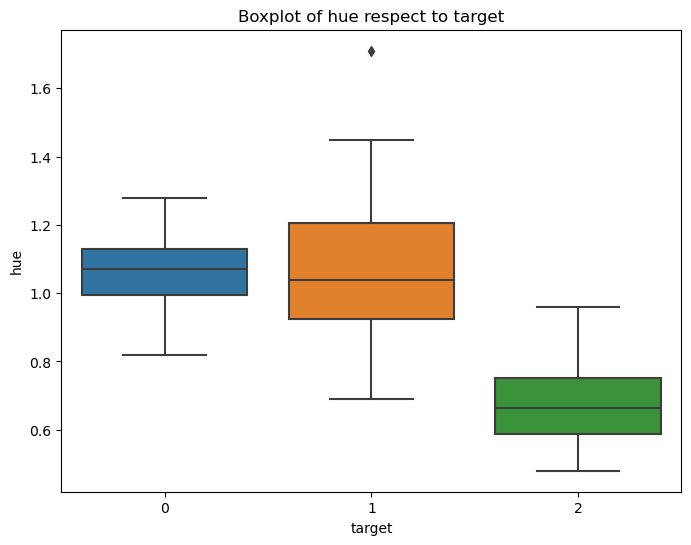

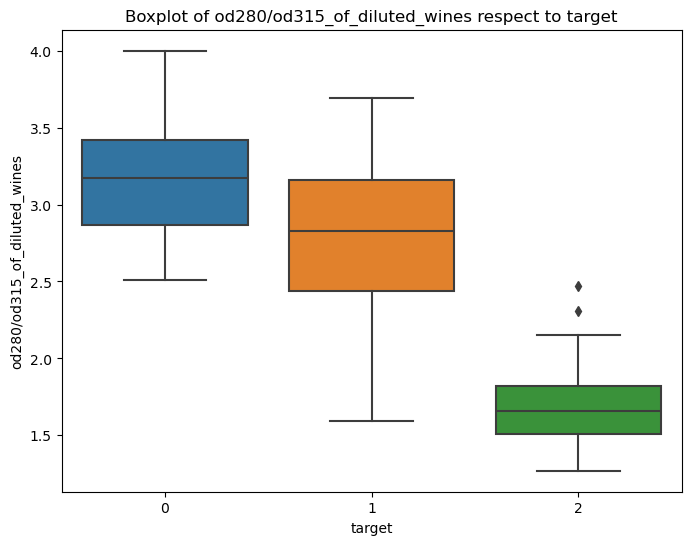

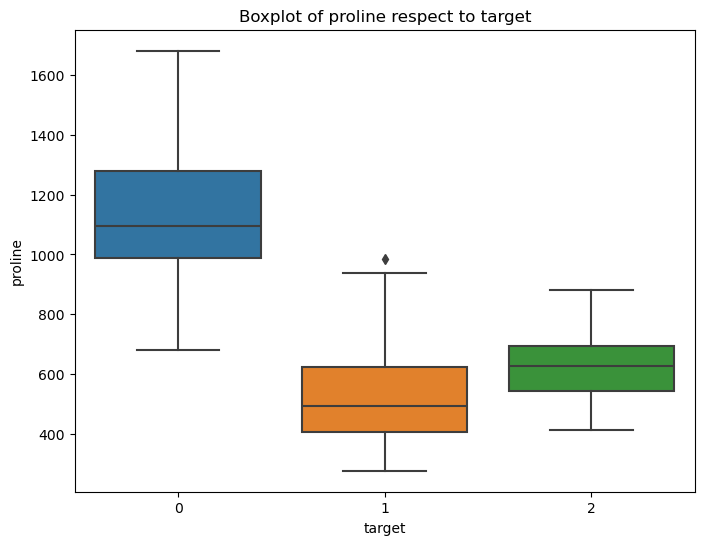

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Numerical variables
numerical_features = df.drop('target', axis=1).columns

# Create boxplots
for feature in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='target', y=feature, data=df)
    plt.title(f'Boxplot of {feature} respect to target')
    plt.show()

### The boxplots highlight distinct distributions for key variables across wine classes. 'Flavanoids' and 'total_phenols' show clear separation between classes, indicating strong interdependence and discriminatory power.  Similarly, 'od280/od315_of_diluted_wines' exhibits distinct distributions per class, confirming its link with 'flavanoids'. Conversely, 'malic_acid' shows an opposing trend, with medians and distributions varying inversely with the 'target' variable, confirming a negative correlation. 

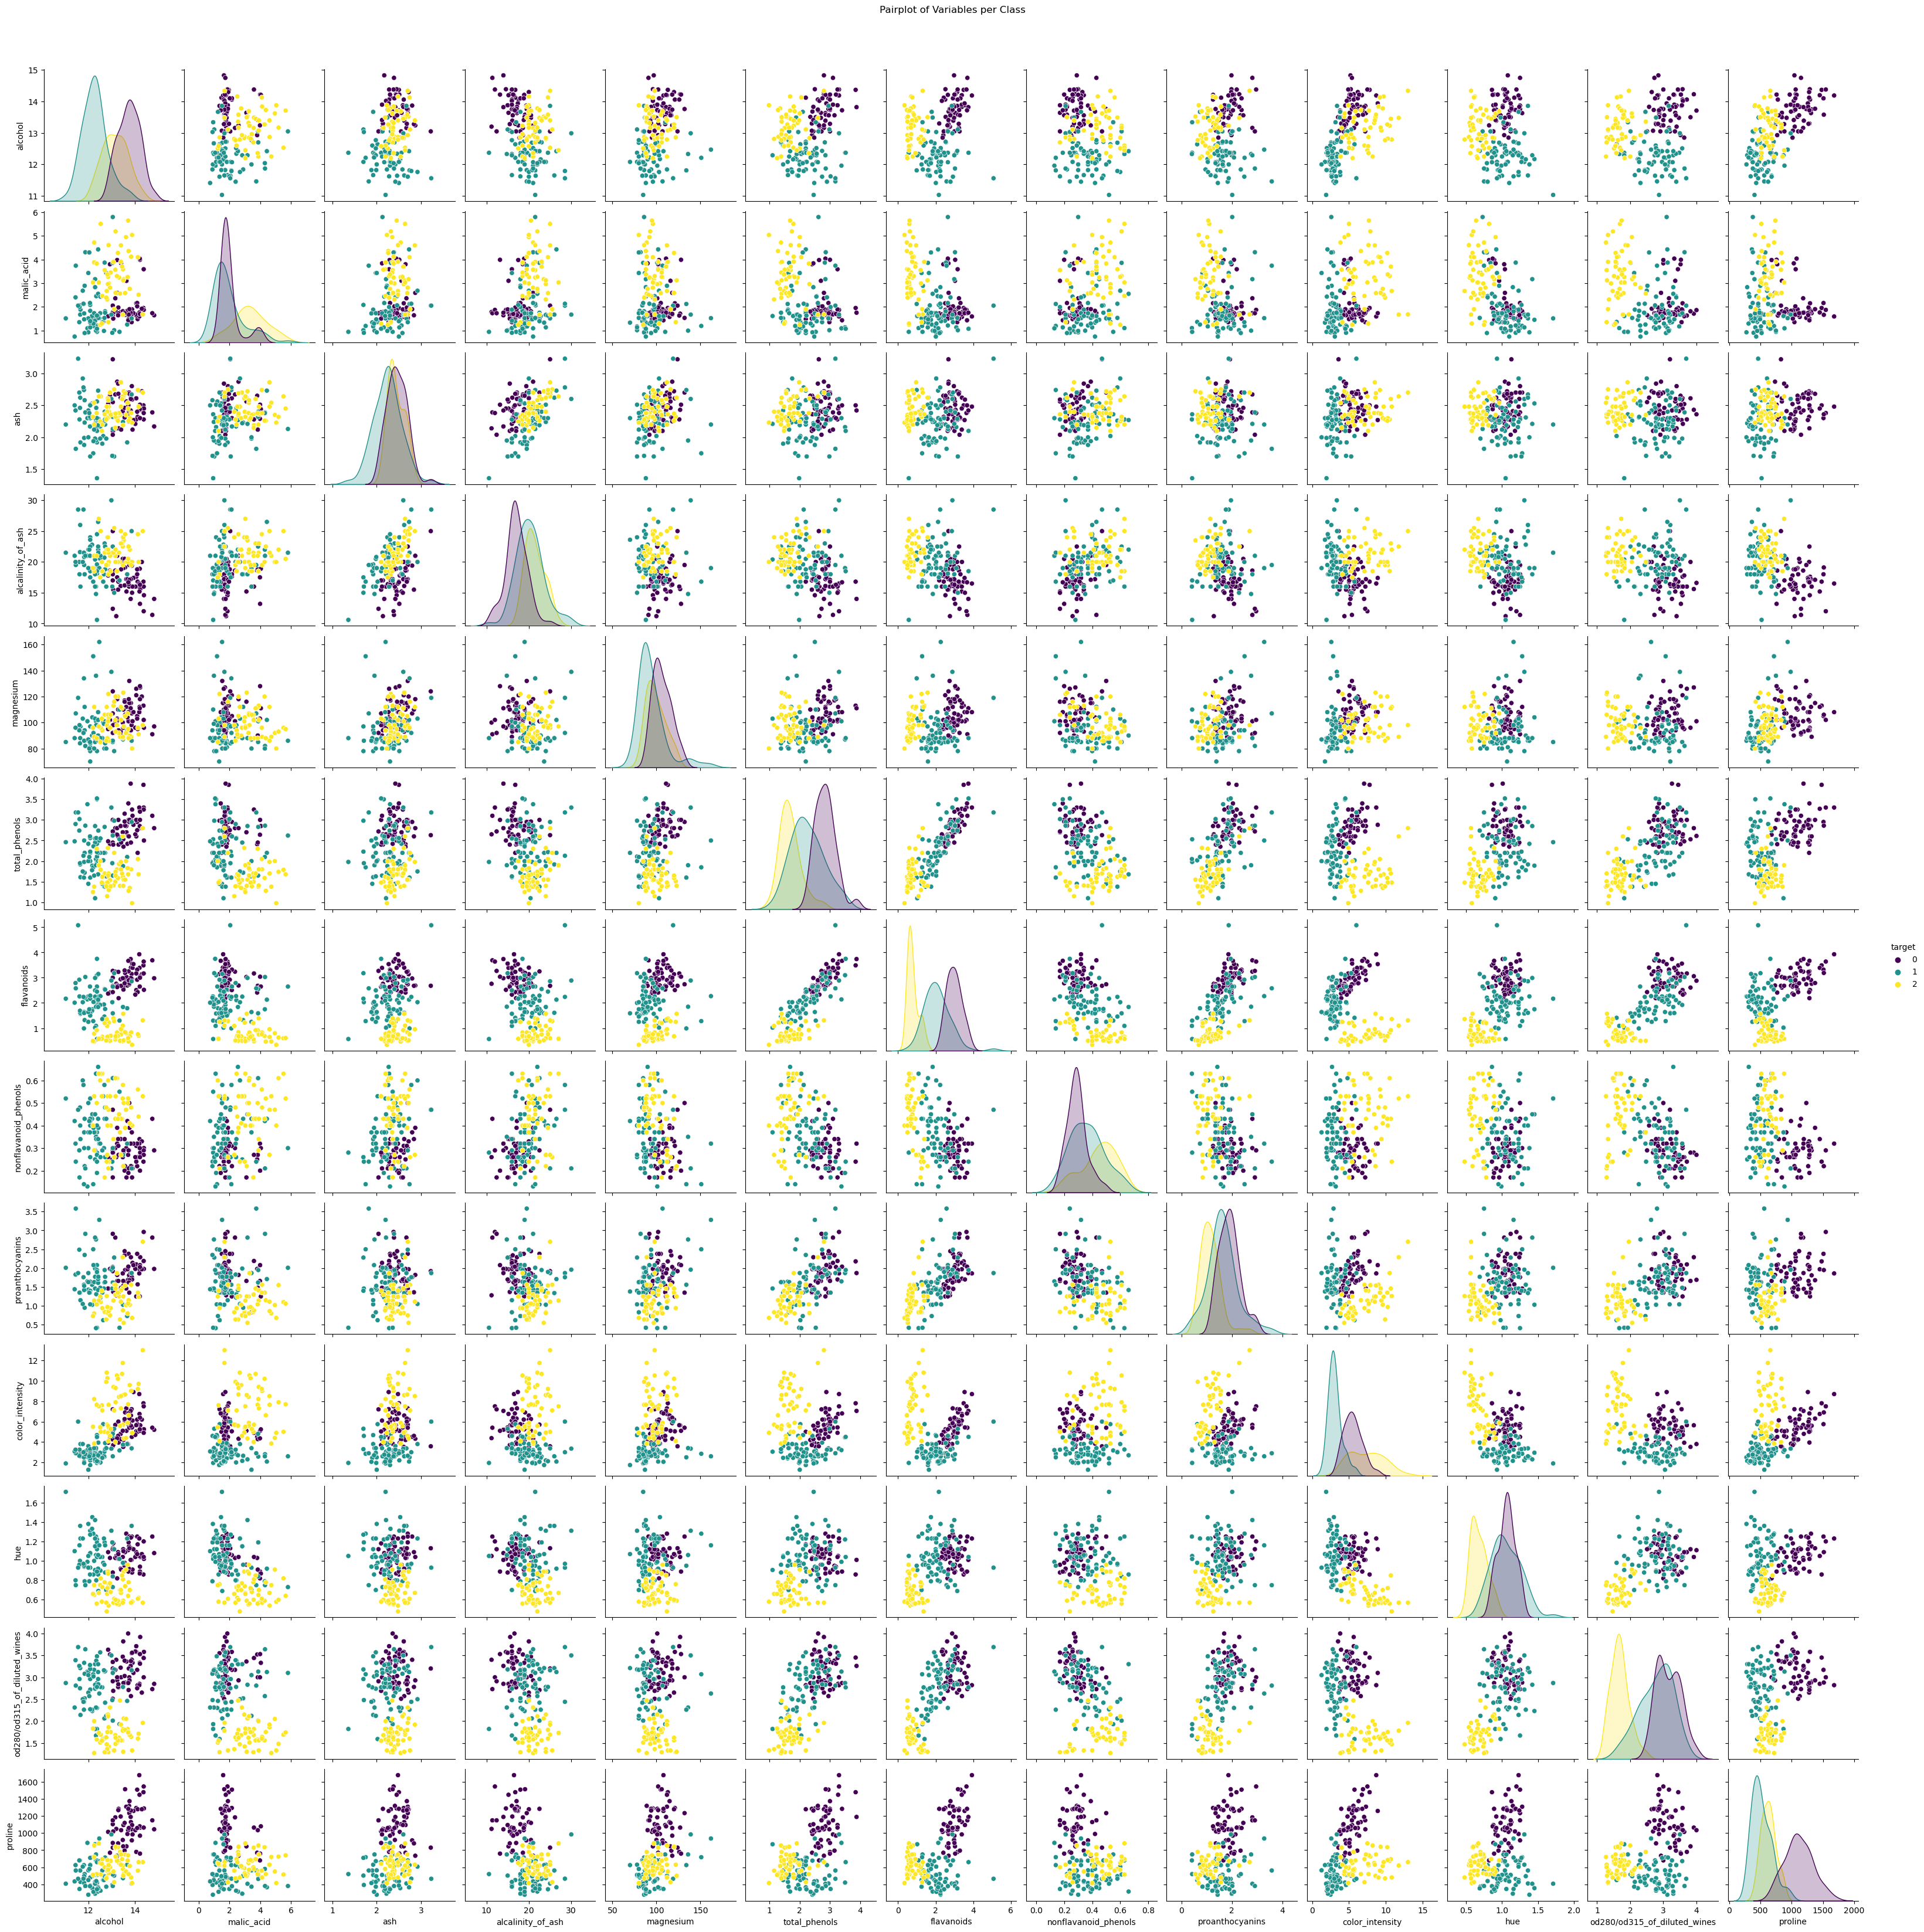

In [7]:
# Pairplot for visualisation relationship between variables
sns.pairplot(df, hue='target', palette='viridis')
plt.suptitle('Pairplot of Variables per Class', y=1.02)
plt.show()

### This pairplot matrix reveals the relationships between all pairs of variables in the "wine" dataset, colored by the target variable (wine type). Clear separations between classes are observed for some pairs of variables, indicating a strong discriminatory ability. For example, combinations involving "flavanoids", "total_phenols", and "proline" show a distinct separation of classes.

In [8]:
# Missing values
print(df.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [9]:
# Data treatment
X = df.drop('target', axis=1)
y = df['target']

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Data Normalisation 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Hyperparameters definition
svm_params = {'kernel': ['linear', 'rbf'], 'C': [1, 10]}
rf_params = {'n_estimators': [50, 100], 'max_depth': [None, 5]}

# Creatingof models
svm_model = SVC()
rf_model = RandomForestClassifier()

# GridSearchCV
svm_grid = GridSearchCV(svm_model, svm_params, cv=5)
rf_grid = GridSearchCV(rf_model, rf_params, cv=5)

# Fit the grids
svm_grid.fit(X_train_scaled, y_train)
rf_grid.fit(X_train, y_train)

# Get best models and evaluate
svm_best = svm_grid.best_estimator_
rf_best = rf_grid.best_estimator_

y_pred_svm = svm_best.predict(X_test_scaled)
y_pred_rf = rf_best.predict(X_test)

# Precision calculate
accuracy_svm = accuracy_score(y_test, y_pred_svm)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f'SVM Accuracy: {accuracy_svm:.2f}')
print(f'Random Forest Accuracy: {accuracy_rf:.2f}')

SVM Accuracy: 1.00
Random Forest Accuracy: 1.00


#### This result indicates that both models: SVM and Random Forest, achieved an accuracy of 1.00 (100%) on the test set. This means that the models correctly predicted the wine type for each sample in the test set.

In [10]:
# Classification Reports
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

# Best Hyperparameters
print("Best Hyperparameters for SVM:", svm_grid.best_params_)
print("Best Hyperparameters for Random Forest:", rf_grid.best_params_)

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        14
           1       1.00      1.00      1.00        14
           2       1.00      1.00      1.00         8

    accuracy                           1.00        36
   macro avg       1.00      1.00      1.00        36
weighted avg       1.00      1.00      1.00        36

Best Hyperparameters for SVM: {'C': 1, 'kernel': 'rbf'}
Best Hyperparameters for Random Forest: {'max_depth': 5, 'n_estimators': 100}


# CONCLUSION
The analysis of the "wine" dataset demonstrated the effectiveness of the SVM and Random Forest models for multiclass classification. After rigorous data preprocessing, including normalization and optimal hyperparameter search via GridSearchCV, both models achieved a perfect accuracy of 1.00 on the test set. Detailed classification reports confirm this excellent performance, with precision, recall and F1 scores of 1.00 for each class. The best hyperparameters identified for each model provide valuable insights for future applications. This phase of the project successfully demonstrated the ability of these algorithms to accurately classify different types of wine based on their chemical characteristics.

# Part2: Real-World Classification Challenge

## CONTEXT
This study falls within the field of medical classification, with the specific objective of developing and evaluating machine learning models for breast cancer diagnosis. Using the Wisconsin dataset, a widely recognized dataset in the scientific community, the study aims to explore the ability of algorithms to distinguish malignant from benign tumors. The focus is not only on the performance of the models, but also on their interpretability, in order to understand which factors are most determining in the diagnosis.

## VARIABLES DESCRIPTIONS 

The Breast Cancer Wisconsin dataset contains features computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. They describe characteristics of the cell nuclei present in the image.

**Features:**

* **radius (mean of distances from center to points on the perimeter):** The average radius of the tumor mass.
* **texture (standard deviation of gray-scale values):** A measure of the tumor's texture.
* **perimeter:** The perimeter of the tumor mass.
* **area:** The area of the tumor mass.
* **smoothness (local variation in radius lengths):** A measure of the smoothness of the tumor.
* **compactness (perimeter^2 / area - 1.0):** A measure of how compact the tumor is.
* **concavity (severity of concave portions of the contour):** A measure of the severity of concave portions of the tumor.
* **concave points (number of concave portions of the contour):** The number of concave portions of the tumor.
* **symmetry:** A measure of the symmetry of the tumor.
* **fractal dimension ("coastline approximation" - 1):** A measure of the fractal dimension of the tumor.

**Notes:**

* For each of the above features, the mean, standard error, and "worst" (largest) value were computed for each image, resulting in 30 features.
* All feature values are recorded with four significant digits.

**Target Variable:**

* **diagnosis:**
    * M = Malignant (cancerous)
    * B = Benign (non-cancerous)

### Data loading

In [11]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['diagnosis'] = cancer.target 

# Descriptive Analysis
print(df.info())
print(df.describe())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

### Data Visualisation

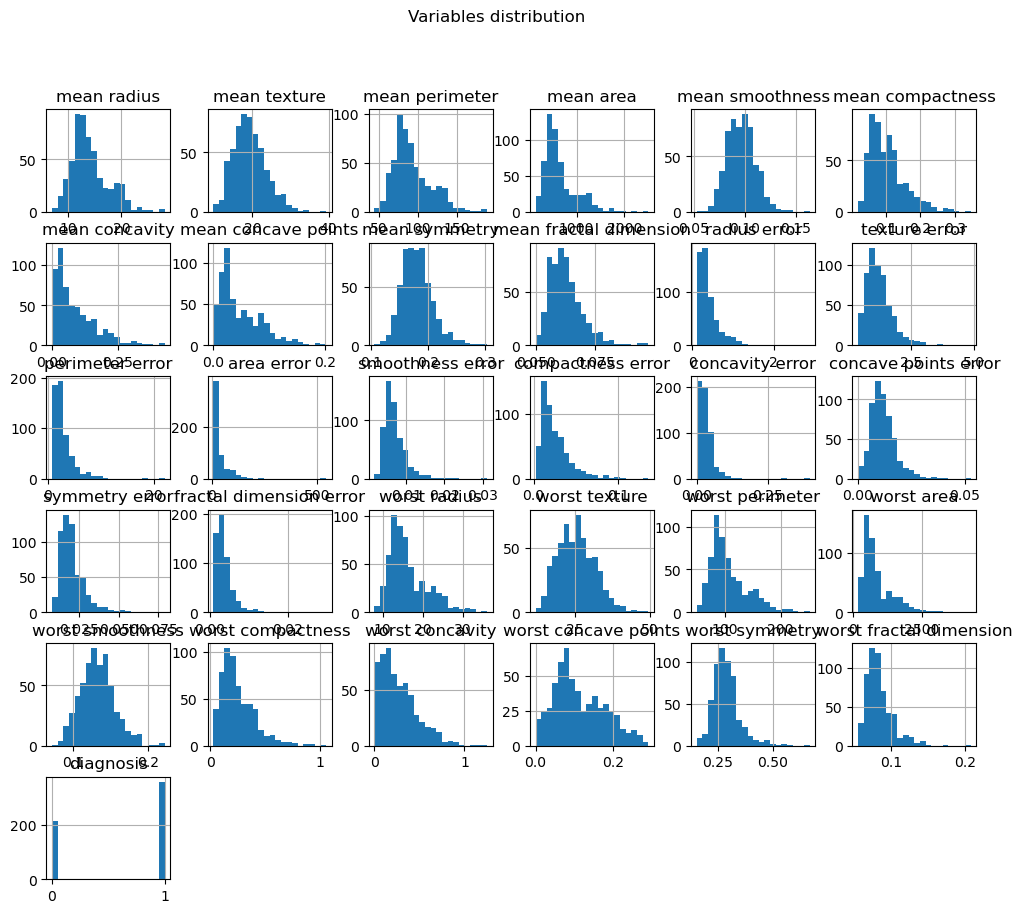

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Variables distribution
df.hist(figsize=(12, 10), bins=20)
plt.suptitle('Variables distribution')
plt.show()

Most variables, such as "mean radius", "mean texture", and other mean measures, show a right-skewed distribution, suggesting a concentration of tumors with lower values ​​for these features. Error-related variables ("radius error", "texture error", etc.) are strongly right-skewed, indicating that most tumors have low measurement errors. The "diagnosis" variable reveals an imbalance, with more benign tumors (0) than malignant ones (1).

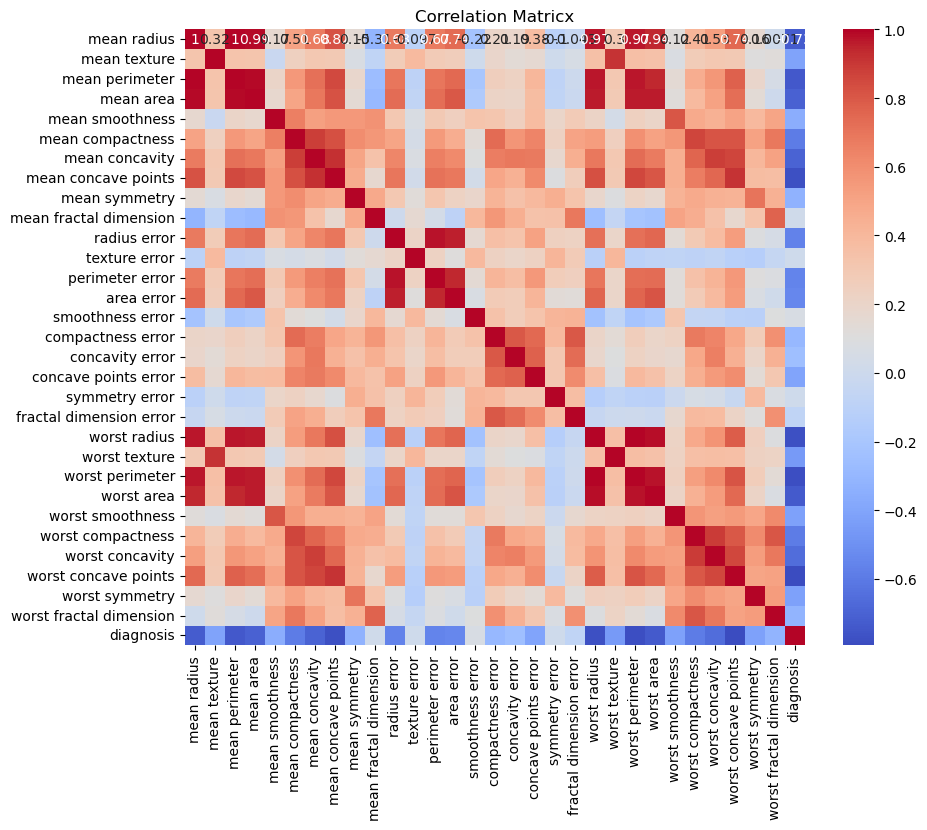

In [13]:
# Correlation Matricx
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matricx')
plt.show()

A strong positive correlation is observed between the variables "mean radius", "mean perimeter", "mean area", and "worst radius", "worst perimeter", "worst area", suggesting that they measure similar aspects of tumor size. The variable "diagnosis" shows a positive correlation with variables related to tumor size and shape, indicating that malignant tumors tend to have higher values ​​for these characteristics.

### Data Preprocessing

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Standardization

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Data Split

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardization (applied only to training data for GridSearchCV and SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Models implementation
## SVMs
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train_scaled, y_train)
## Random Forests
rf_model = RandomForestClassifier(n_estimators=100, max_depth=None)
rf_model.fit(X_train, y_train)

# GridsearchCV for SVMs
svm_params = {'kernel': ['linear', 'rbf'], 'C': [1, 10]}
svm_grid = GridSearchCV(SVC(), svm_params, cv=5)
svm_grid.fit(X_train_scaled, y_train)

# GridsearchCV for Random Forests
rf_params = {'n_estimators': [50, 100], 'max_depth': [None, 5]}
rf_grid = GridSearchCV(RandomForestClassifier(), rf_params, cv=5)
rf_grid.fit(X_train, y_train)

# Predictions 
y_pred_svm = svm_grid.best_estimator_.predict(X_test_scaled)
y_pred_rf = rf_grid.best_estimator_.predict(X_test)


accuracy_svm = accuracy_score(y_test, y_pred_svm)
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print(f'SVM Accuracy: {accuracy_svm:.2f}')
print(f'Random Forest Accuracy: {accuracy_rf:.2f}')




SVM Accuracy: 0.98
Random Forest Accuracy: 0.96


The SVM achieves an accuracy of 98%, while the Random Forest achieves 96%. These high scores indicate that both models are very effective in predicting whether a tumor is malignant or benign, with the SVM being slightly more accurate.

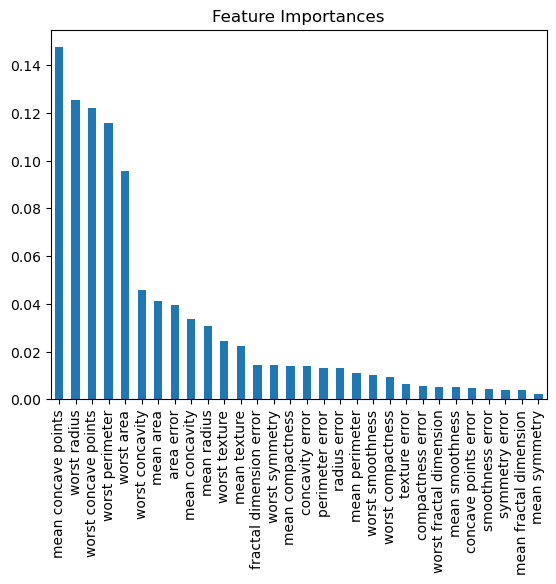

In [15]:
# Models interpretation
importances = rf_grid.best_estimator_.feature_importances_
feature_importances = pd.Series(importances, index=X.columns)
feature_importances.sort_values(ascending=False).plot(kind='bar')
plt.title('Feature Importances')
plt.show()

The variables related to tumor size and shape ("worst radius", "worst concave points", "worst perimeter", "worst area") stand out as the most influential in the model predictions, highlighting their crucial role in the classification between malignant and benign tumors. The importance of the features gradually decreases, indicating that variables related to measurement errors and some symmetry features have a lesser impact on the results

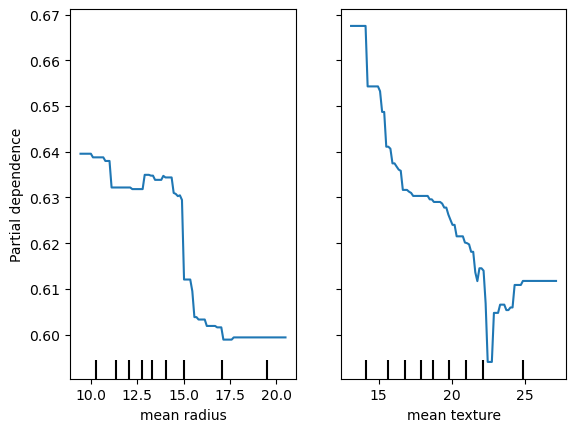

In [16]:
from sklearn.inspection import PartialDependenceDisplay

PartialDependenceDisplay.from_estimator(rf_grid.best_estimator_, X_train, features=[0, 1])
plt.show()

Partial dependence of diagnostic probability on the features "mean radius" and "mean texture" in a Random Forest model. For "mean radius", an increase from 10 to 17.5 is associated with a strong decrease in diagnostic probability, suggesting that a larger mean radius reduces the risk of malignancy. For "mean texture", a similar trend is observed, although less pronounced and with fluctuations, indicating that a larger mean texture has a slight negative influence on diagnostic probability.

## CONCLUSION
Feature importance analysis revealed that tumor size and shape are the most important factors for classification, confirming medical intuition. Partial dependency plots furthered this analysis by illustrating how individual features, such as mean radius and mean texture, influence the probability of diagnosis. In summary, this part not only developed high-performance models but also provided valuable insights into the key factors associated with breast cancer diagnosis, highlighting the importance of interpretability in medicine.

# END